        # Lesson 7.5 · ARIMA, SARIMA and SARIMAX
        ### The Box-Jenkins workflow: identify → estimate → diagnose → forecast

        | | |
        |---|---|
        | ⏱️ **Time** | about 100 minutes |
        | 📚 **Before you start** | Lessons 7.1 – 7.4 |
        | 🧪 **Format** | lesson → worked examples → exercises with hints → recap |

        ## 🎯 What you will be able to do after this notebook
        - Explain **AR**, **I** and **MA** components and recognise them in ACF/PACF patterns
- Fit **ARIMA**, choose orders by **AIC**, and **diagnose** residuals
- Add seasonality with **SARIMA** and external drivers with **SARIMAX**
- Forecast with **prediction intervals** and back-transform from logs

> 🌾 **The story so far.** Smoothing models treat the past as a weighted average. ARIMA asks a sharper question: *how much of today's surprise carries over into tomorrow?* It models the **echoes** (autocorrelation) directly.

In [1]:
import sys, pathlib, warnings
# Find the course folder (works no matter where Jupyter was started)
ROOT = next(p for p in [pathlib.Path.cwd(), *pathlib.Path.cwd().parents] if (p / "src" / "agrilab.py").exists())
sys.path.insert(0, str(ROOT / "src"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import agrilab as ag          # our helper library: src/agrilab.py

from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.tsa.arima_process import ArmaProcess
from statsmodels.tsa.stattools import pacf, acf
from statsmodels.stats.diagnostic import acorr_ljungbox
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
import itertools
warnings.filterwarnings("ignore")   # (after imports: statsmodels re-enables its own warnings when imported)
ag.setup_plots()
ag.set_seed(42)
print("Setup complete. Course folder:", ROOT.name)

Setup complete. Course folder: course


## 1 · Three building blocks

**AR(p): AutoRegressive:** today is a weighted sum of the last *p* days plus a fresh shock $\varepsilon_t$.
$$y_t = c + \phi_1 y_{t-1} + \dots + \phi_p y_{t-p} + \varepsilon_t$$
*Memory lives in the **values**.*

**MA(q): Moving Average of shocks:** today is a weighted sum of the last *q* **shocks**.
$$y_t = \mu + \varepsilon_t + \theta_1 \varepsilon_{t-1} + \dots + \theta_q \varepsilon_{t-q}$$
*Memory lives in the **surprises**.* (Not the same as a moving *average of prices*! Confusing name, sorry; the statisticians did it.)

**I(d): Integrated:** difference the series $d$ times to make it stationary, model the differences.

Put together: **ARIMA(p, d, q)**. Add a seasonal part and you get **SARIMA(p,d,q)(P,D,Q)$_s$**, where $s$ is the season length
(12 for monthly, 52 for weekly). Add external regressors $x_t$ and you get **SARIMAX**.

### Let's *see* AR and MA by simulating them
We know the truth, so we can check whether the ACF/PACF reveal it.

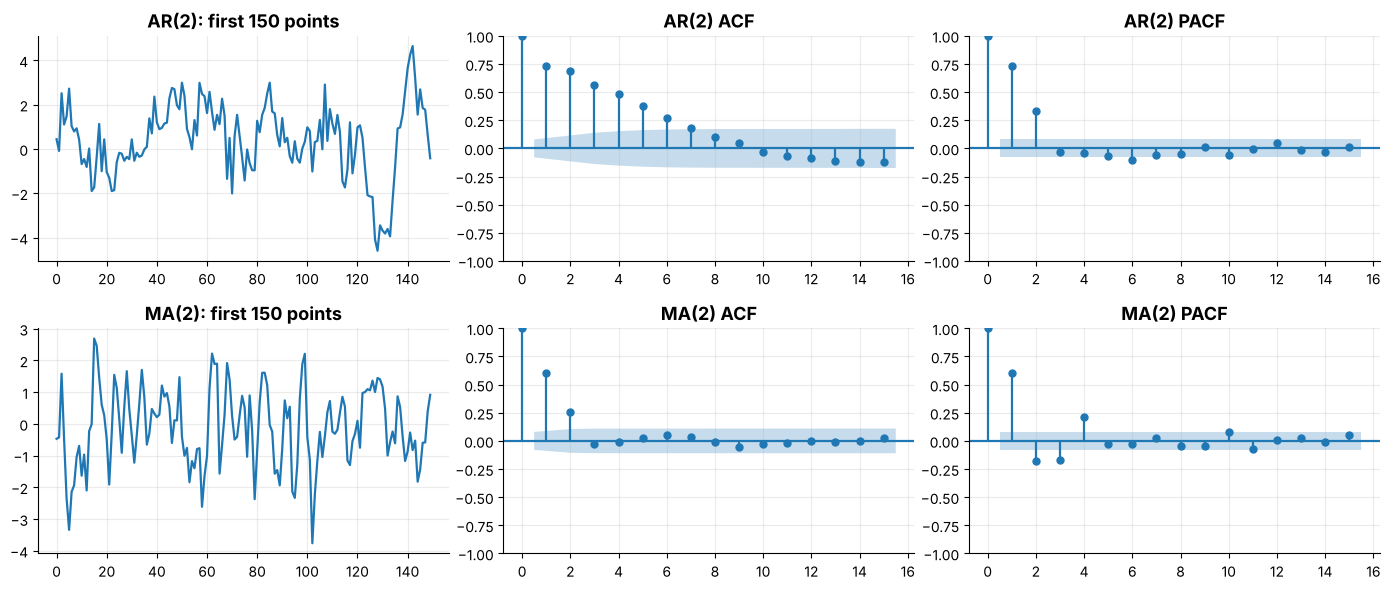

In [2]:
np.random.seed(5)
# NOTE statsmodels' convention: the AR polynomial is [1, -phi1, -phi2, ...]
ar2 = ArmaProcess(ar=[1, -0.55, -0.30], ma=[1]).generate_sample(600)
ma2 = ArmaProcess(ar=[1], ma=[1, 0.7, 0.5]).generate_sample(600)

fig, axes = plt.subplots(2, 3, figsize=(14, 6))
for row, (name, x) in enumerate([("AR(2)", ar2), ("MA(2)", ma2)]):
    axes[row, 0].plot(x[:150]); axes[row, 0].set_title(f"{name}: first 150 points")
    plot_acf(x, lags=15, ax=axes[row, 1], title=f"{name} ACF"); plot_pacf(x, lags=15, ax=axes[row, 2], title=f"{name} PACF", method="ywm")
plt.tight_layout(); plt.show()

| | ACF | PACF |
|---|---|---|
| **AR(p)** | tails off (gradually) | **cuts off after lag p** |
| **MA(q)** | **cuts off after lag q** | tails off (gradually) |

Row 1 shows PACF dying after lag 2 (AR(2)); row 2 shows ACF dying after lag 2 (MA(2)). Memorise this table: it's the Box-Jenkins "fingerprint".

---
### 🧩 Exercise 1: Identify the order  ⭐

The array `mystery` below was generated by an AR process of unknown order (1 to 4).
Using the PACF with 12 lags and the 95 % bound `1.96/sqrt(n)`, find the **largest significant lag** and store it as `p_hat`.

<details><summary>💡 Hint 1: gentle nudge</summary>

`vals = pacf(mystery, nlags=12, method='ywm')`, then ignore `vals[0]`.

</details>

<details><summary>💡 Hint 2: bigger nudge</summary>

Significant lags: `[k for k in range(1, 13) if abs(vals[k]) > 1.96/np.sqrt(len(mystery))]`.

</details>

<details><summary>💡 Hint 3: almost the answer</summary>

`p_hat = max(sig)`. With a clean AR process there should be a clear cut-off.

</details>

*Write your answer in the next cell, then run the check cell below it. Stuck after the hints? The full solution is in `solutions/`.*

In [3]:
mystery = ArmaProcess(ar=[1, -0.5, 0.0, -0.35], ma=[1]).generate_sample(800, distrvs=np.random.default_rng(11).standard_normal)
vals = pacf(mystery, nlags=12, method="ywm")
sig = [k for k in range(1, 13) if abs(vals[k]) > 1.96 / np.sqrt(len(mystery))]
p_hat = max(sig)
print("significant PACF lags:", sig, "-> p =", p_hat)

significant PACF lags: [1, 2, 3] -> p = 3


In [4]:
ag.check("p_hat = 3", p_hat == 3, "look for the last big spike before the bars stay inside the blue band")

✅  p_hat = 3


True

---
## 2 · The Box-Jenkins workflow

1. **Identify**: plot, transform (log), difference until stationary, read ACF/PACF for candidate orders.
2. **Estimate**: fit candidates by maximum likelihood; compare by **AIC** (lower = better trade-off of fit vs complexity).
3. **Diagnose**: are the residuals *white noise*? (no autocorrelation left, roughly normal)
4. **Forecast**: with prediction intervals; then validate **out-of-sample**.

We work with the **log** of weekly Central tomato prices (stabilises the growing swings; differences become % changes).

In [5]:
wk = ag.price_series("tomato", "Central", "W")
ly = np.log(wk)
train_l, test_l = ly.iloc[:-26], ly.iloc[-26:]           # hold out the last half-year
print("train:", len(train_l), "weeks | test:", len(test_l), "weeks")

train: 497 weeks | test: 26 weeks


### Step 1–2: Identification and a first fit
From Lesson 7.1 we know one difference makes the log-price stationary ($d=1$). Let's fit a modest **ARIMA(2,1,1)** and read the summary.

In [6]:
m1 = ARIMA(train_l, order=(2, 1, 1)).fit()
print(m1.summary().tables[1])
print(f"AIC = {m1.aic:.1f}   BIC = {m1.bic:.1f}")

                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1          0.8848      0.166      5.329      0.000       0.559       1.210
ar.L2         -0.0682      0.103     -0.662      0.508      -0.270       0.134
ma.L1         -0.4954      0.162     -3.055      0.002      -0.813      -0.178
sigma2         0.0034      0.000     26.840      0.000       0.003       0.004
AIC = -1401.3   BIC = -1384.4


**Reading the coefficient table:** `ar.L1`, `ar.L2` are $\phi_1,\phi_2$; `ma.L1` is $\theta_1$; `sigma2` is the shock variance.
Check the `P>|z|` column: coefficients with p > 0.05 might be dropped. A large `ar.L1` near 1 is the "persistence" we saw in the ACF.

### Choosing orders: an AIC grid
**AIC** $= 2k - 2\ln\hat L$: the model is rewarded for fitting well and penalised for each parameter $k$.
Only compare AICs for the **same differencing order and the same data**.

In [7]:
rows = []
for p, q in itertools.product(range(0, 4), range(0, 4)):
    try:
        f = ARIMA(train_l, order=(p, 1, q)).fit()
        rows.append(dict(p=p, q=q, AIC=f.aic, BIC=f.bic))
    except Exception:
        pass
grid = pd.DataFrame(rows).sort_values("AIC")
grid.head(6).round(1).reset_index(drop=True)

,p,q,AIC,BIC
0,2,3,-1460.9,-1435.7
1,3,2,-1446.0,-1420.7
2,3,3,-1408.8,-1379.3
3,3,0,-1407.7,-1390.9
4,1,3,-1407.7,-1386.7
5,3,1,-1407.2,-1386.2


### Step 3: Diagnose the residuals
If the model captured all the structure, residuals are **white noise**: no autocorrelation, constant variance, bell-shaped.
The **Ljung-Box test** asks: *"Is there any autocorrelation left up to lag L?"* $H_0$: residuals are white noise.
A small p-value (< 0.05) = structure remains = the model missed something.

Best by AIC: ARIMA(2,1,3)
    lb_stat  lb_pvalue
10  12.3003     0.2655
26  32.7135     0.1706
52  87.5890     0.0015


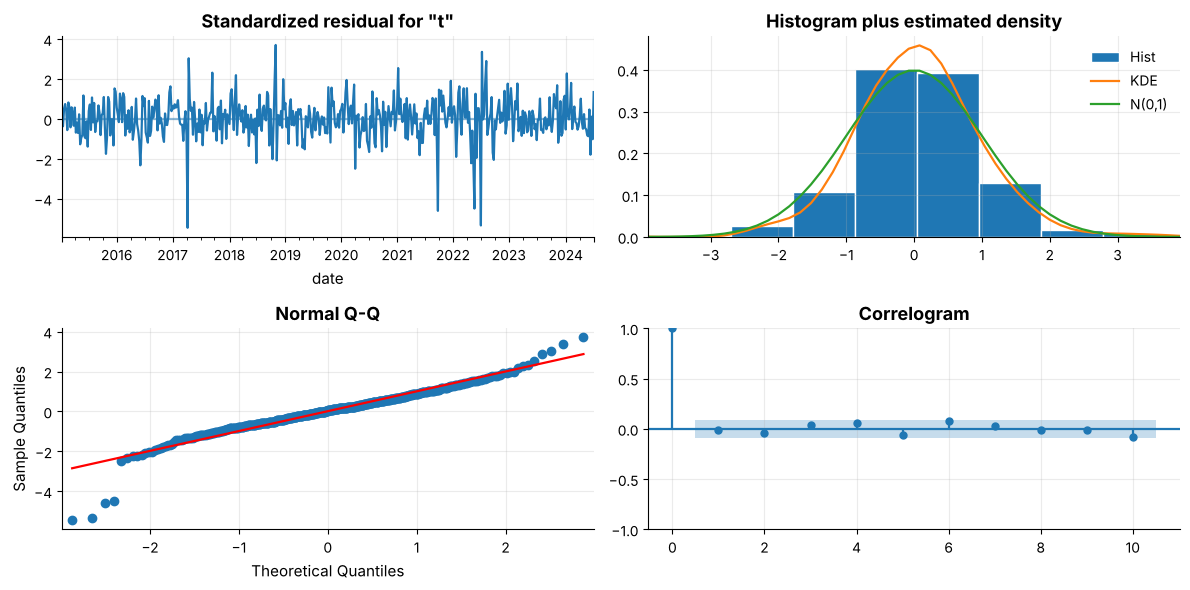

In [8]:
best_p, best_q = int(grid.iloc[0].p), int(grid.iloc[0].q)
best = ARIMA(train_l, order=(best_p, 1, best_q)).fit()
print(f"Best by AIC: ARIMA({best_p},1,{best_q})")
print(acorr_ljungbox(best.resid[1:], lags=[10, 26, 52], return_df=True).round(4))
fig = best.plot_diagnostics(figsize=(12, 6)); plt.tight_layout(); plt.show()

How to read the four panels: **(top-left)** residuals should look like noise around 0; **(top-right)** histogram close to the normal curve;
**(bottom-left)** points near the line = normal; **(bottom-right)** correlogram: no spikes outside the band.
Likely finding: short lags look fine but **lag 52 is not**: the yearly seasonality isn't modelled. The diagnostics *told us what to fix*.

### Step 4: Forecast with uncertainty

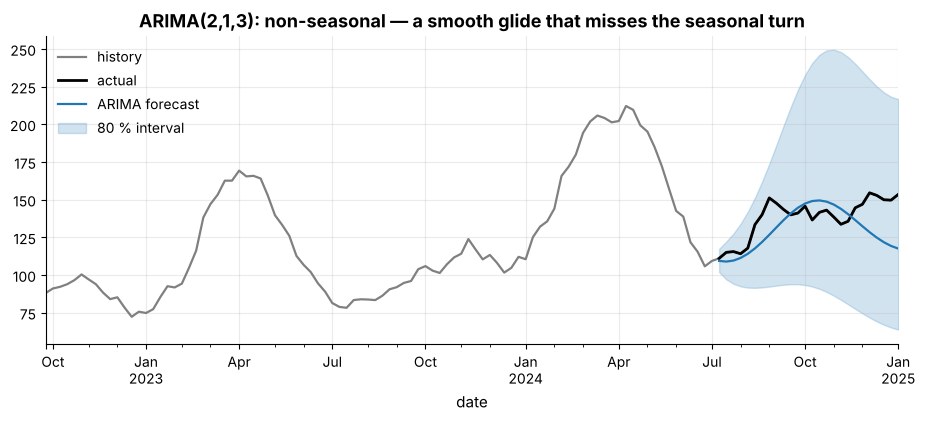

In [9]:
fc = best.get_forecast(26)
mean = np.exp(fc.predicted_mean)                              # back-transform from log to price
ci = np.exp(fc.conf_int(alpha=0.2))                           # 80 % interval
fig, ax = plt.subplots(figsize=(11, 4))
wk.iloc[-120:].plot(ax=ax, color="gray", label="history")
wk.iloc[-26:].plot(ax=ax, color="black", lw=2, label="actual")
mean.plot(ax=ax, color="tab:blue", label="ARIMA forecast")
ax.fill_between(ci.index, ci.iloc[:, 0], ci.iloc[:, 1], alpha=.2, color="tab:blue", label="80 % interval")
ax.legend(); ax.set_title(f"ARIMA({best_p},1,{best_q}): non-seasonal: a smooth glide that misses the seasonal turn"); plt.show()

> 💡 **Professor's aside.** ARIMA with no seasonal term and d=1 forecasts something close to a **drifting random walk**: a nearly straight line with a widening fan. The widening cone is honest: uncertainty *should* grow with the horizon.

---
### 🧩 Exercise 2: Compare two candidates by AIC  ⭐

Using `train_l`, fit **ARIMA(1,1,0)** and **ARIMA(0,1,1)**. Store their AICs in `aic_ar1` and `aic_ma1`, and put the
winning order tuple (e.g. `(1, 1, 0)`) in `winner`.

<details><summary>💡 Hint 1: gentle nudge</summary>

`ARIMA(train_l, order=(1, 1, 0)).fit().aic`

</details>

<details><summary>💡 Hint 2: bigger nudge</summary>

Same for `(0, 1, 1)`.

</details>

<details><summary>💡 Hint 3: almost the answer</summary>

`winner = (1, 1, 0) if aic_ar1 < aic_ma1 else (0, 1, 1)`

</details>

*Write your answer in the next cell, then run the check cell below it. Stuck after the hints? The full solution is in `solutions/`.*

In [10]:
aic_ar1 = ARIMA(train_l, order=(1, 1, 0)).fit().aic
aic_ma1 = ARIMA(train_l, order=(0, 1, 1)).fit().aic
winner = (1, 1, 0) if aic_ar1 < aic_ma1 else (0, 1, 1)
print(round(aic_ar1, 1), round(aic_ma1, 1), "->", winner)

-1387.4 -1353.6 -> (1, 1, 0)


In [11]:
ref = ARIMA(train_l, order=(1, 1, 0)).fit().aic
ag.check("AIC of ARIMA(1,1,0) is right", aic_ar1 is not None and np.isclose(aic_ar1, ref))
ag.check("winner has the lower AIC", winner == ((1, 1, 0) if aic_ar1 < aic_ma1 else (0, 1, 1)))

✅  AIC of ARIMA(1,1,0) is right
✅  winner has the lower AIC


True

---
### 🧩 Exercise 3: Is the residual really white?  ⭐⭐

For the model `best` above, run the Ljung-Box test at **lag 26** on `best.resid[1:]` (skip the first residual: it is an initialisation artefact).
Store the p-value in `lb_p` (a float) and set `white = lb_p > 0.05`.
Then write one sentence in the string `verdict` explaining what a failure would mean.

<details><summary>💡 Hint 1: gentle nudge</summary>

`acorr_ljungbox(resid, lags=[26], return_df=True)` returns a DataFrame with columns `lb_stat` and `lb_pvalue`.

</details>

<details><summary>💡 Hint 2: bigger nudge</summary>

`lb_p = float(result['lb_pvalue'].iloc[0])`.

</details>

<details><summary>💡 Hint 3: almost the answer</summary>

`verdict`: any sensible sentence, e.g. 'autocorrelation remains, so the model missed structure such as seasonality'.

</details>

*Write your answer in the next cell, then run the check cell below it. Stuck after the hints? The full solution is in `solutions/`.*

In [12]:
res = acorr_ljungbox(best.resid[1:], lags=[26], return_df=True)
lb_p = float(res["lb_pvalue"].iloc[0])
white = bool(lb_p > 0.05)
verdict = "A small p-value means autocorrelation remains in the residuals: the model missed structure (e.g. seasonality)."
print(round(lb_p, 4), white)

0.1706 True


In [13]:
ag.check("lb_p is a probability", isinstance(lb_p, float) and 0 <= lb_p <= 1)
ag.check("white is consistent with lb_p", white == (lb_p > 0.05))
ag.check("you wrote a verdict", isinstance(verdict, str) and len(verdict) > 20)

✅  lb_p is a probability
✅  white is consistent with lb_p
✅  you wrote a verdict


True

---
## 3 · SARIMA: teaching ARIMA about the calendar

$$\text{SARIMA}(p,d,q)\,(P,D,Q)_s$$

The lowercase part models short-term echoes; the uppercase part models echoes **at seasonal lags** ($s, 2s, \dots$).
$D=1$ means a *seasonal difference* $y_t - y_{t-s}$ (removing the repeating pattern as differencing removed the trend).

The classic starting recipe for monthly data with trend + seasonality: the so-called **"airline model"**:
$$\text{SARIMA}(0,1,1)(0,1,1)_{12}$$
Season length **s = 12** on monthly data is cheap. (Weekly data with s = 52 is possible but slow: we'll use Fourier terms instead in §4.)

                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1         -0.2277      0.406     -0.560      0.575      -1.024       0.569
ma.L1          0.4538      0.389      1.168      0.243      -0.308       1.215
ma.S.L12      -0.8479      0.217     -3.912      0.000      -1.273      -0.423
sigma2         0.0094      0.001      6.642      0.000       0.007       0.012
AIC: -151.2


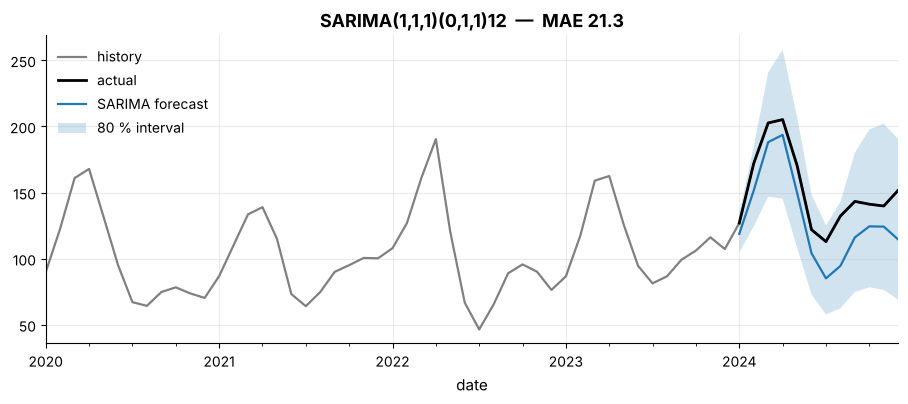

In [14]:
mon = ag.price_series("tomato", "Central", "ME")
lm = np.log(mon)
tr, te = lm.iloc[:-12], lm.iloc[-12:]

sar = SARIMAX(tr, order=(1, 1, 1), seasonal_order=(0, 1, 1, 12)).fit(disp=False)
print(sar.summary().tables[1]); print("AIC:", round(sar.aic, 1))

fc = sar.get_forecast(12); mean = np.exp(fc.predicted_mean); ci = np.exp(fc.conf_int(alpha=0.2))
fig, ax = plt.subplots(figsize=(11, 4))
mon.iloc[-60:].plot(ax=ax, color="gray", label="history"); mon.iloc[-12:].plot(ax=ax, color="black", lw=2, label="actual")
mean.plot(ax=ax, label="SARIMA forecast"); ax.fill_between(ci.index, ci.iloc[:, 0], ci.iloc[:, 1], alpha=.2, label="80 % interval")
ax.legend(); ax.set_title(f"SARIMA(1,1,1)(0,1,1)12; MAE {ag.mae(mon.iloc[-12:], mean):.1f}"); plt.show()

---
### 🧩 Exercise 4: SARIMA vs the seasonal-naive baseline  ⭐⭐

Using the monthly log split `tr, te` above, build a **12-month** forecast from:
- your own **SARIMA(1,1,0)(1,1,0)₁₂** model: back-transform with `np.exp` → `sarima_fc`
- the seasonal-naive baseline in *price* units (`ag.seasonal_naive_forecast(mon.iloc[:-12], 12, m=12)`) → `snaive_fc`

Compute `mae_sarima` and `mae_snaive` against `mon.iloc[-12:]`. Set `sarima_wins = mae_sarima < mae_snaive`.

<details><summary>💡 Hint 1: gentle nudge</summary>

`SARIMAX(tr, order=(1,1,0), seasonal_order=(1,1,0,12)).fit(disp=False)`

</details>

<details><summary>💡 Hint 2: bigger nudge</summary>

`sarima_fc = np.exp(model.forecast(12)).to_numpy()`: the model works in logs, so exponentiate!

</details>

<details><summary>💡 Hint 3: almost the answer</summary>

`actual = mon.iloc[-12:]`; `ag.mae(actual, sarima_fc)`.

</details>

*Write your answer in the next cell, then run the check cell below it. Stuck after the hints? The full solution is in `solutions/`.*

In [15]:
actual = mon.iloc[-12:]
model = SARIMAX(tr, order=(1, 1, 0), seasonal_order=(1, 1, 0, 12)).fit(disp=False)
sarima_fc = np.exp(model.forecast(12)).to_numpy()
snaive_fc = ag.seasonal_naive_forecast(mon.iloc[:-12], 12, m=12)
mae_sarima, mae_snaive = ag.mae(actual, sarima_fc), ag.mae(actual, snaive_fc)
sarima_wins = bool(mae_sarima < mae_snaive)
print(round(mae_sarima, 2), round(mae_snaive, 2), sarima_wins)

25.6 39.82 True


In [16]:
ag.check("forecast has 12 values in PRICE units (not logs)", sarima_fc is not None and len(sarima_fc) == 12 and np.mean(sarima_fc) > 20,
         "did you forget np.exp()?")
ag.check("MAEs computed", mae_sarima is not None and mae_snaive is not None)
ag.check("sarima_wins is consistent", sarima_wins == (mae_sarima < mae_snaive))

✅  forecast has 12 values in PRICE units (not logs)
✅  MAEs computed
✅  sarima_wins is consistent


True

### ⚠️ One split is a coin-flip: a lesson in humility
Same data, same model: only the **length of the holdout** changes. Watch the verdict flip:

In [17]:
for H in (12, 24):
    tr_, act_ = lm.iloc[:-H], mon.iloc[-H:]
    f = np.exp(SARIMAX(tr_, order=(1, 1, 1), seasonal_order=(0, 1, 1, 12)).fit(disp=False).forecast(H)).to_numpy()
    s = ag.seasonal_naive_forecast(mon.iloc[:-H], H, m=12)
    print(f"holdout = last {H:2d} months:  SARIMA MAE = {ag.mae(act_, f):5.1f}   seasonal-naive MAE = {ag.mae(act_, s):5.1f}")

holdout = last 12 months:  SARIMA MAE =  21.3   seasonal-naive MAE =  39.8


holdout = last 24 months:  SARIMA MAE =  44.8   seasonal-naive MAE =  33.8


On the 12-month holdout SARIMA wins easily; on 24 months a sudden price run-up in the last two years (visible in Lesson 7.1's trend panel) hurts
every model that extrapolates a trend. **Neither number is "the truth"**: each is one noisy sample. This is precisely why Lesson 7.3 insisted on
*many* origins (walk-forward) before declaring a winner. Never crown a model from a single split.

---
## 4 · SARIMAX: letting outside information in

The **X** means *eXogenous* regressors: other series that help explain ours.

$$y_t = \beta^\top x_t + \eta_t,\qquad \eta_t \sim \text{ARIMA/SARIMA errors}$$

Two uses for us:
1. **Fourier terms**: smooth sin/cos waves encode *yearly seasonality* on weekly data without a 52-lag seasonal block.
2. **Drivers**: rainfall from ~2 months ago (Lesson 7.2), fuel prices, etc.

> 🚨 **The exogenous catch.** To forecast $h$ steps ahead you need the *future* values of $x$. Either they are **known** (calendar → Fourier terms),
> **forecastable**, or you use a **lagged** version that's already observed. Rain that fell 8 weeks ago is known today, so we may forecast 8 weeks ahead with no extra assumptions.

In [18]:
def fourier(index, K=3, period=365.25):
    doy = index.dayofyear.to_numpy()
    cols = {}
    for k in range(1, K + 1):
        cols[f"sin{k}"] = np.sin(2 * np.pi * k * doy / period); cols[f"cos{k}"] = np.cos(2 * np.pi * k * doy / period)
    return pd.DataFrame(cols, index=index)

rain = ag.load_weather().set_index("date")["rainfall_mm"].resample("W").sum().reindex(wk.index)
rain_lag8 = rain.rolling(9, min_periods=1).sum().shift(8).bfill().rename("rain_lag8")      # bfill only touches the very first rows
EXOG_SEAS = fourier(wk.index)
EXOG_FULL = pd.concat([EXOG_SEAS, (rain_lag8 - rain_lag8.mean()) / rain_lag8.std()], axis=1)
EXOG_FULL.head(2).round(2)

,sin1,cos1,sin2,cos2,sin3,cos3,rain_lag8
date,,,,,,,
2015-01-04,0.07,1.00,0.14,0.99,0.20,0.98,-1.34
2015-01-11,0.19,0.98,0.37,0.93,0.54,0.84,-1.34


In [19]:
sx = SARIMAX(train_l, exog=EXOG_FULL.loc[train_l.index], order=(2, 1, 1)).fit(disp=False)
print(sx.summary().tables[1])

                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
sin1           0.2543      0.028      9.030      0.000       0.199       0.309
cos1           0.0877      0.027      3.241      0.001       0.035       0.141
sin2          -0.0584      0.015     -4.003      0.000      -0.087      -0.030
cos2          -0.1866      0.022     -8.591      0.000      -0.229      -0.144
sin3           0.0055      0.009      0.599      0.549      -0.012       0.023
cos3           0.0067      0.009      0.756      0.450      -0.011       0.024
rain_lag8     -0.0241      0.014     -1.717      0.086      -0.052       0.003
ar.L1          0.1676      0.363      0.462      0.644      -0.544       0.879
ar.L2         -0.1529      0.055     -2.799      0.005      -0.260      -0.046
ma.L1         -0.0693      0.368     -0.188      0.851      -0.791       0.653
sigma2         0.0025      0.000     24.111      0.0

Look at the `rain_lag8` coefficient: it is **negative**: more rain two months ago means lower prices today, the physical story we expected, though only borderline significant (p ≈ 0.09) on this training window. A modest p-value doesn't make a driver useless for *forecasting*; the walk-forward test below is the real judge.
Now the fair test: **walk-forward at weekly horizons up to 8**, comparing naive, plain ARIMA, SARIMAX with Fourier only, and SARIMAX with Fourier + rain.

In [20]:
def arima_fp(order):
    def fp(train, h):
        return np.exp(ARIMA(np.log(train), order=order).fit().forecast(h)).to_numpy()
    return fp

def sarimax_fp(cols, order=(2, 1, 1)):
    def fp(train, h):
        i = EXOG_FULL.index.get_loc(train.index[-1])
        res = SARIMAX(np.log(train), exog=EXOG_FULL.loc[train.index, cols], order=order).fit(disp=False)
        return np.exp(res.forecast(h, exog=EXOG_FULL.iloc[i + 1:i + 1 + h][cols])).to_numpy()
    return fp

seas_cols = list(EXOG_SEAS.columns); all_cols = seas_cols + ["rain_lag8"]
models = {"naive": ag.naive_forecast, "ARIMA(2,1,1)": arima_fp((2, 1, 1)),
          "SARIMAX + Fourier": sarimax_fp(seas_cols), "SARIMAX + Fourier + rain": sarimax_fp(all_cols)}
res = {n: ag.walk_forward(wk, f, initial=300, horizon=8, step=8) for n, f in models.items()}
print("origins:", res["naive"].origin_date.nunique())
ag.score_table(res, y_train=wk.iloc[:300])

origins: 27


,MAE,RMSE,MAPE,MASE
SARIMAX + Fourier + rain,8.971,11.686,8.433,2.159
SARIMAX + Fourier,9.342,12.213,8.832,2.248
"ARIMA(2,1,1)",14.849,24.783,14.413,3.574
naive,18.188,26.746,17.520,4.377


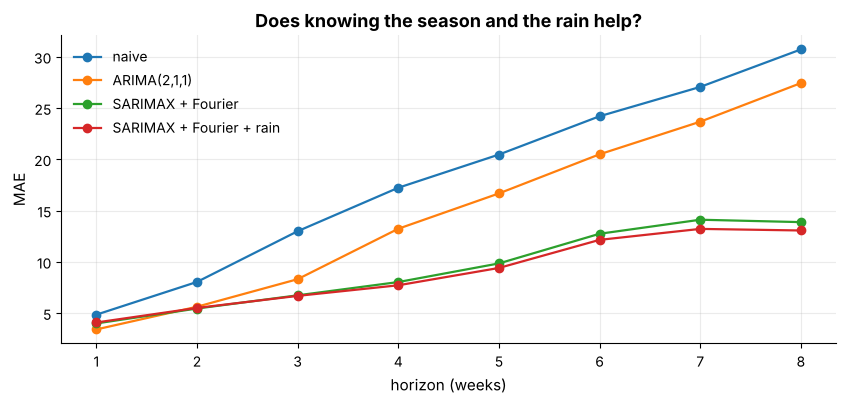

In [21]:
by_h = pd.DataFrame({n: r.groupby("h").apply(lambda d: ag.mae(d.actual, d.forecast)) for n, r in res.items()})
ax = by_h.plot(marker="o", figsize=(10, 4)); ax.set(xlabel="horizon (weeks)", ylabel="MAE", title="Does knowing the season and the rain help?"); plt.show()

The story you should see: at **h = 1** nobody beats naive by much; as the horizon grows, models that *know the season*, and the rain:
separate from the pack. (Because the data are synthetic you can even check the truth: the generator really does contain a rain effect, so SARIMAX *should* find it.)

### Practical advice from the trenches
| Situation | Advice |
|---|---|
| Not sure which orders | Start small: (1,1,1) or the airline model; widen only if diagnostics demand it |
| Fit warns "non-invertible / convergence" | Reduce orders; check differencing; scale the data (log) |
| Weekly or daily seasonal data | Fourier terms in `exog` (+ ARIMA errors) instead of huge seasonal periods |
| Many series (4 crops × 3 markets) | Automate: grid or `pmdarima.auto_arima`: but **still** validate walk-forward |
| Need exogenous at forecast time | Use lags long enough to be known, or forecast the regressors first |
| Forecast needs to be non-negative | Model the **log** and exponentiate (as we did) |

## 🎓 Mini-quiz
1. A PACF cuts off after lag 2 and the ACF decays slowly. Which model family?
2. ARIMA(1,1,1)(0,1,1)$_{12}$: what does each part do?
3. Why can't you just feed *tomorrow's* rainfall into SARIMAX to forecast tomorrow's price?

<details><summary>Answers</summary>

1. **AR(2)**.
2. AR(1) + MA(1) on first-differenced data (trend removed) and a seasonal MA(1) on 12-month-differenced data (seasonality removed).
3. At forecast time tomorrow's rain is unknown. Using it is a leak (or at best requires a weather *forecast*, with its own error).
</details>

        ---
        ## 🧾 Recap
        - **AR** = memory of values, **MA** = memory of shocks, **I** = differencing for stationarity.
- ACF/PACF fingerprints suggest orders; **AIC** compares candidates; **Ljung-Box + residual plots** diagnose.
- **SARIMA** adds seasonal AR/MA/differencing at lag *s*; **SARIMAX** adds external regressors (Fourier terms, lagged drivers).
- Model **logs** for positive, growing-variance data; exponentiate forecasts (and intervals).
- Exogenous regressors need *known* future values: lag them or forecast them.
- Always confirm with **walk-forward** error by horizon.

**Next up:** Lesson 7.6: machine-learning forecasting: lag features with regression, random forests, gradient boosting and XGBoost.